# Lab 1 — Interpretable by Design Models

---

This lab covers three **interpretable-by-design** classifiers and how to extract meaningful explanations from each:

| Model | Interpretability type |
|---|---|
| **Decision Tree** | Global (tree structure, feature importance, depth trade-off) + Local (decision path) |
| **Logistic Regression** | Global (coefficients, odds ratios, correlation matrix) |
| **K-Nearest Neighbors** | Local (example-based, neighbor inspection + visualisation) |

**Guide:**
- ⚙️ Preprocessing recap
- 🌳 Decision Tree
- 📈 Logistic Regression
- 👥 KNN

---

## ⚙️ 0 - Preprocessing Recap (~10 min)

We are using the **Diabetes prediction dataset** and the same pipeline from Lab 0.
Rather than stepping through every operation again, this section is structured as a **quick recap** —
each cell highlights one key concept with a reminder of *why* it matters.

> 💡 The goal here is to consolidate what you learned in Lab 0, not to learn new things!
> By the end of this section you should be able to answer: *what would go wrong if you skipped each step?*

### ⚙️ Step 1 — Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn import tree

#### Exercise 0.1

Load the data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#@title Exercise 0.1 Solution

# ── Load the dataset ──────────────────────────────────────────────────────────
# Uncomment the line that matches your environment:
# df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/XAI_202627/labs/Lab01_Interpretable_by_Design/diabetes.csv')  # Google Drive
df = pd.read_csv('diabetes.csv')   # Local / GitHub

In [ ]:

df.columns = [c.lower().replace('-', '_') for c in df.columns]
if 'class' in df.columns:
    df.rename(columns={'class': 'diabetes'}, inplace=True)
df['diabetes'] = (df['diabetes'].astype(str).str.strip().str.lower()
                  .map({'tested_positive': 1, 'tested_negative': 0,
                        '1': 1, '0': 0, 'positive': 1, 'negative': 0})
                  .astype(int))

print(f"Loaded {len(df)} rows  |  Columns: {df.columns.tolist()}")
df.head()

Loaded 100000 rows  |  Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'hba1c_level', 'blood_glucose_level', 'diabetes']


,gender,age,hypertension,heart_disease,smoking_history,bmi,hba1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### ⚙️ Step 2 — Check Class Balance & Duplicates

> 🔑 **Key reminder:** an imbalanced dataset means **accuracy is a misleading metric**.
> If 91% of patients are non-diabetic, a model that always predicts "no diabetes" gets 91% accuracy — and is completely useless.
> Always check balance *before* splitting so you can choose `stratify=` and the right evaluation metric.

In [ ]:
print("Class distribution:")
print(df['diabetes'].value_counts())
print(f"\nImbalance ratio: {df['diabetes'].value_counts()[0] / df['diabetes'].value_counts()[1]:.1f}:1")

Class distribution:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Imbalance ratio: 10.8:1


#### Exercise 0.2

Remove duplicates

In [ ]:
#@title Exercise 0.2 Solution

#### START CODE HERE (~3 lines of code) ####
n_dupes = df.duplicated(keep=False).sum()
print(f"\nDuplicate rows: {n_dupes}")
df.drop_duplicates(inplace=True)
#### END CODE HERE ####


Duplicate rows: 6939


In [ ]:
print(f"Rows after dedup: {len(df)}")
#Rows after dedup: 96146

Rows after dedup: 96146


### ⚙️ Step 3 — Stratified Train/Test Split

> 🔑 **Key reminder:** split *before* any transformation. Fitting scalers or encoders
> on the full dataset lets test-set statistics leak into your preprocessing, making
> your evaluation overly optimistic — this is called **data leakage**.
> `stratify=` preserves the class ratio in both subsets.

#### Exercise 0.3
Stratified Train/Test Split: Split 80% train / 20% test, shuffle=True, random_state=42, stratify by 'survived

In [ ]:
#@title Exercise 0.3 Solution


#### START CODE HERE ####
# Split 80% train / 20% test, shuffle=True, random_state=42, stratify by 'survived'
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=True, random_state=42, stratify=df['diabetes'])
#### END CODE HERE ####

In [ ]:
print(f"Train: {len(df_train)} rows  |  Test: {len(df_test)} rows")
print(f"\nTrain class balance:\n{df_train['diabetes'].value_counts()}")
print(f"\nTest class balance:\n{df_test['diabetes'].value_counts()}")

Train: 76916 rows  |  Test: 19230 rows

Train class balance:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Test class balance:
diabetes
0    17534
1     1696
Name: count, dtype: int64


### ⚙️ Step 4 — Feature Engineering & Encoding

> 🔑 **Key reminder:** ML models need numbers. Categorical features must be encoded,
> but the *type* of encoding matters:
> - **Ordinal Encoder** — when categories have a natural order (e.g. Child < Young < Adult < Senior)
> - **One-Hot Encoder** — when categories have no order (e.g. gender)
> Using the wrong encoder imposes false numeric relationships the model will exploit.

#### Exercise 0.4



*   Discretize age into 4 ordered bins `age_bins   = [0, 14, 24, 50, 100]
age_labels = ['Child (0-14]', 'Young (14-24]', 'Adults (24-50]', 'Senior (50+]']`
*  Merge sparse smoking categories, 'former' and 'not current' mean the same thing — combining them avoids sparse encoding
* Remove rare 'Other' gender rows (too few to encode reliably)
* Ordinal encode: smoking_history and age_disc (both have natural order)
* One-hot encode: gender (no natural order)



In [ ]:
#@title Exercise 0.4 Solution

# ── Discretize age into 4 ordered bins ───────────────────────────────────────
age_bins   = [0, 14, 24, 50, 100]
age_labels = ['Child (0-14]', 'Young (14-24]', 'Adults (24-50]', 'Senior (50+]']
for d in [df_train, df_test]:
    d['age_disc'] = pd.cut(d['age'], bins=age_bins, labels=age_labels)
    d.drop(columns=['age'], inplace=True)

# ── Merge sparse smoking categories ──────────────────────────────────────────
# 'former' and 'not current' mean the same thing — combining them avoids sparse encoding
for d in [df_train, df_test]:
    d.loc[d['smoking_history'] == 'former', 'smoking_history'] = 'not current'

# ── Remove rare 'Other' gender rows (too few to encode reliably) ──────────────
df_train = df_train[df_train['gender'] != 'Other'].copy()
df_test  = df_test[df_test['gender']  != 'Other'].copy()

# ── Ordinal encode: smoking_history and age_disc (both have natural order) ────
smoking_order = ["never", "not current", "No Info", "current", "ever"]
ord_enc = OrdinalEncoder(categories=[smoking_order, age_labels])
ord_enc.fit(df_train[['smoking_history', 'age_disc']])   # fit on train only!
for d in [df_train, df_test]:
    d[['smoking_history', 'age_disc']] = ord_enc.transform(d[['smoking_history', 'age_disc']])

# ── One-hot encode: gender (no natural order) ─────────────────────────────────
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(df_train[['gender']])                             # fit on train only!
for d in [df_train, df_test]:
    ohe_cols = pd.DataFrame(ohe.transform(d[['gender']]),
                            columns=ohe.get_feature_names_out(), index=d.index)
    d.drop(columns=['gender'], inplace=True)
    for col in ohe_cols.columns:
        d[col] = ohe_cols[col]


In [ ]:
print("Encoding done. Columns:", df_train.columns.tolist())
df_train.head(3)

Encoding done. Columns: ['hypertension', 'heart_disease', 'smoking_history', 'bmi', 'hba1c_level', 'blood_glucose_level', 'diabetes', 'age_disc', 'gender_Female', 'gender_Male']


,hypertension,heart_disease,smoking_history,bmi,hba1c_level,blood_glucose_level,diabetes,age_disc,gender_Female,gender_Male
79000,0,0,2.0,23.87,5.7,126,0,2.0,0.0,1.0
32011,0,0,1.0,33.03,4.0,126,0,3.0,1.0,0.0
95559,0,0,2.0,27.32,6.6,126,0,2.0,1.0,0.0


### ⚙️ Step 5 — Scaling & Final Split

> 🔑 **Key reminder:** scaling is essential for distance-based models (KNN) and
> gradient-based models (Logistic Regression), which are sensitive to feature magnitude.
> Decision trees are *scale-invariant* — they only care about split thresholds, not absolute values.
> We scale anyway so all three models share the same `X_train` / `X_test`.

#### Exercise 0.5


* Apply `MixMaxScaler()` on `scale_cols = ['bmi', 'hba1c_level', 'blood_glucose_level', 'age_disc', 'smoking_history']
* Extract train and test `X_train`, `X_test`
* Extract train and test labels  `y_train`, `y_test`
``

In [ ]:
df_train.head(3)

,hypertension,heart_disease,smoking_history,bmi,hba1c_level,blood_glucose_level,diabetes,age_disc,gender_Female,gender_Male
79000,0,0,2.0,23.87,5.7,126,0,2.0,0.0,1.0
32011,0,0,1.0,33.03,4.0,126,0,3.0,1.0,0.0
95559,0,0,2.0,27.32,6.6,126,0,2.0,1.0,0.0


In [ ]:
#@title Exercise 0.5 Solution
scale_cols = ['bmi', 'hba1c_level', 'blood_glucose_level', 'age_disc', 'smoking_history']

scaler = MinMaxScaler()
df_train[scale_cols] = scaler.fit_transform(df_train[scale_cols])  # fit on train only!
df_test[scale_cols]  = scaler.transform(df_test[scale_cols])

In [ ]:
# ── Extract X / y ─────────────────────────────────────────────────────────────
y_train = df_train['diabetes'];  X_train = df_train.drop('diabetes', axis=1)
y_test  = df_test['diabetes'];   X_test  = df_test.drop('diabetes',  axis=1)
feature_names = X_train.columns.tolist()

print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}")
print(f"Features: {feature_names}")

X_train: (76902, 9)  |  X_test: (19226, 9)
Features: ['hypertension', 'heart_disease', 'smoking_history', 'bmi', 'hba1c_level', 'blood_glucose_level', 'age_disc', 'gender_Female', 'gender_Male']


> ✅ **Preprocessing complete.** The three rules to always remember:
> 1. Split *before* fitting any transformer
> 2. Fit transformers on training data only, then `.transform()` both sets
> 3. Choose your encoding based on whether categories have a natural order

---

## Exercise 1 — Decision Tree 🌳

Decision trees are **interpretable by design**: the tree structure *is* the explanation — no separate explanation method needed.

They give a **transparent** and **intuitive** representation of the decision-making
process followed by the model. This transparency allows domain experts to easily
understand and validate the model's predictions.

---

**Global interpretability** — inspecting the whole tree. The measures for the global interpretability are:
- **Depth** → shallower = simpler, more interpretable
- **Node count / splits** → proxy for complexity. A larger tree with more nodes and splits may capture intricate
patterns in the data but could also lead to overtting and decreased
interpretability
- **Feature importances** → which features drive most decisions (via Gini impurity reduction)

**Local interpretability** — local path for a single prediction.Then, as mesures for the local interpretability there is:
- **Length of the decision path** → the exact sequence of rules that routed this instance to its leaf

### Your tasks
1. Fit a `DecisionTreeClassifier`.
  
> * Visualize the decision tree obtained. Are you able to interpret the decision
> * Try again with `max_depth=4` and compare the two trees. Which one is the
  most interpretable?

2. Analyze **Global Interpretability**:
Continue visualizing the obtained decision tree with `max_depth=4` .

> * Which attributes are the **most discriminating**? Plot the feature importances and then analyze the values.
> * Calculate the size of the decision tree in terms of the number of nodes,
subdivisions, and depth. How these metrics affect the interpretability of the
decision tree globally?

3. Analyze **Local Interpretability**:
Consider the instances *100, 150 and 200* of the train dataset.

> * What are the individual paths? What are the instances allocated in the
paths?
> * For each of the previous instances, calculate the **length** of each path from
the root node to the leaf node to which the instance belongs. How does the
length of these paths contribute to the interpretability of the decision tree
locally?

### Exercise 1.1 — Fit & Visualise

* Train a `DecisionTreeClassifier` and plot it.
* Use the model to predict and print its accuracy

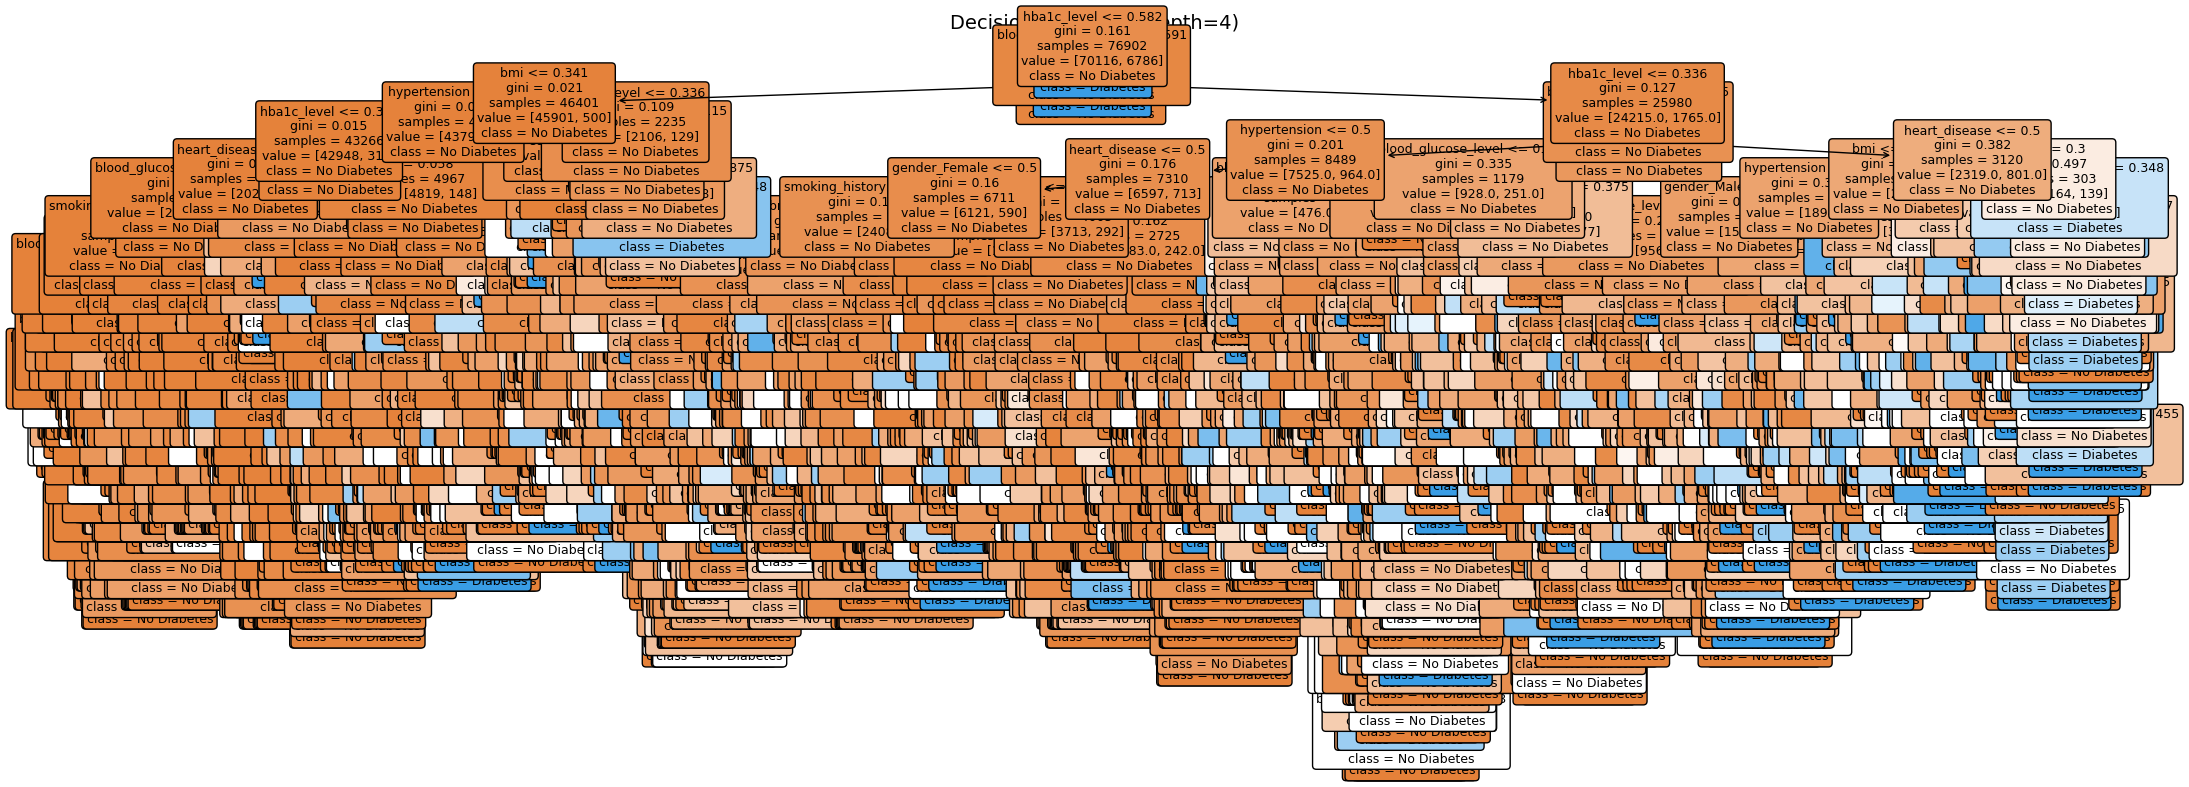

In [ ]:
#@title Exercise 1.1 Solution


#### START CODE HERE ####
# define the model
model = tree.DecisionTreeClassifier()
# fit the model
model.fit(X_train, y_train)
# extract the feature names
feature_names = X_train.columns



# This is the code to plot the decision tree dt
plt.figure(figsize=(22, 8))
tree.plot_tree(model, feature_names=feature_names,
               class_names=['No Diabetes', 'Diabetes'],
               filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=4)", fontsize=14)
plt.tight_layout()
plt.show()


#### END CODE HERE ####

In [ ]:
# Decision Tree Predict
y_pred = model.predict(X_test)
print('Model accuracy: ', model.score(X_test, y_test)*100)

Model accuracy:  95.14199521481326


### Exercise 1.2 — Max Depth 4

* Train
* Plot
* create `classification_report`  and `ConfusionMatrixDisplay`

[Text(0.75, 0.9, 'hba1c_level <= 0.582\ngini = 0.161\nsamples = 76902\nvalue = [70116, 6786]'),
 Text(0.625, 0.7, 'blood_glucose_level <= 0.591\ngini = 0.095\nsamples = 73819\nvalue = [70116, 3703]'),
 Text(0.6875, 0.8, 'True  '),
 Text(0.5, 0.5, 'age_disc <= 0.833\ngini = 0.061\nsamples = 72381\nvalue = [70116, 2265]'),
 Text(0.25, 0.3, 'bmi <= 0.341\ngini = 0.021\nsamples = 46401\nvalue = [45901, 500]'),
 Text(0.125, 0.1, 'gini = 0.017\nsamples = 44166\nvalue = [43795, 371]'),
 Text(0.375, 0.1, 'gini = 0.109\nsamples = 2235\nvalue = [2106, 129]'),
 Text(0.75, 0.3, 'hba1c_level <= 0.336\ngini = 0.127\nsamples = 25980\nvalue = [24215.0, 1765.0]'),
 Text(0.625, 0.1, 'gini = 0.0\nsamples = 10031\nvalue = [10031, 0]'),
 Text(0.875, 0.1, 'gini = 0.197\nsamples = 15949\nvalue = [14184, 1765]'),
 Text(0.75, 0.5, 'gini = 0.0\nsamples = 1438\nvalue = [0, 1438]'),
 Text(0.875, 0.7, 'gini = 0.0\nsamples = 3083\nvalue = [0, 3083]'),
 Text(0.8125, 0.8, '  False')]

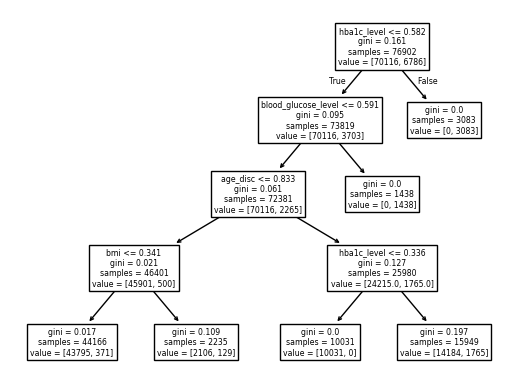

In [ ]:
#@title Exercise 1.2 Solution


#### START CODE HERE -- Decision Tree max_depth=4 ####
# define the model with max_depth = 4
model = tree.DecisionTreeClassifier(max_depth=4)
# fit the model
model.fit(X_train, y_train)
# extract the feature names
feature_names = X_train.columns
tree.plot_tree(model, feature_names=feature_names)
#### END CODE HERE ####

In [ ]:
# Decision Tree Predict
y_pred = model.predict(X_test)
print('Model accuracy: ', model.score(X_test, y_test)*100)

Model accuracy:  97.16009570373453



--- Classification Report (DT, depth=4) ---
              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.98     17530
    Diabetes       1.00      0.68      0.81      1696

    accuracy                           0.97     19226
   macro avg       0.98      0.84      0.90     19226
weighted avg       0.97      0.97      0.97     19226



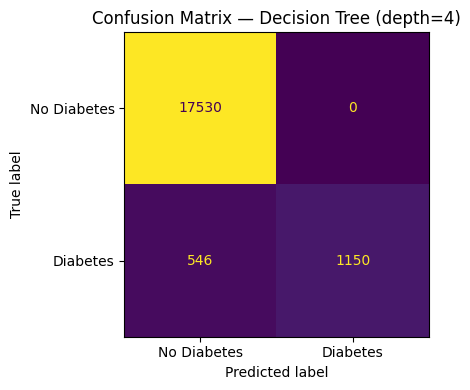

In [ ]:
print("\n--- Classification Report (DT, depth=4) ---")
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes']))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes','Diabetes'])
fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, colorbar=False)
ax.set_title('Confusion Matrix — Decision Tree (depth=4)')
plt.tight_layout()

#### Exercise 1.2b

* Create a 'Depth vs Accuracy' loop ranging over different depth sizes (e.g., `depths = range(1, 10)`)  
* return the best performing tree

In [ ]:
#@title Exercise 1.2b Solution


# ── 1.1 Depth vs Accuracy ────────────────────────────────────────
depths = range(1, 10)
train_accs, test_accs = [], []

for d in depths:
    dt = tree.DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    train_accs.append(dt.score(X_train, y_train))
    test_accs.append(dt.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_accs, 'o-', label='Train accuracy')
ax.plot(depths, test_accs,  's-', label='Test accuracy')
ax.axvline(4, color='red', linestyle='--', label='Depth = 4 (interpretable)')
ax.set_xlabel('Max Depth')
ax.set_ylabel('Accuracy')
ax.set_title('Decision Tree: Depth vs. Accuracy')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('dt_depth_accuracy.png', dpi=120)
plt.close()
print("Saved: dt_depth_accuracy.png")

best_test_depth = depths[np.argmax(test_accs)]
print(f"Best depth by test accuracy: {best_test_depth}")
#print(f"Test accuracy at depth=4: {test_accs[3]:.4f}")
print(f"Test accuracy at best depth ({best_test_depth}): {max(test_accs):.4f}")

Saved: dt_depth_accuracy.png
Best depth by test accuracy: 2
Test accuracy at best depth (2): 0.9716


### Exercise 1.3 — Global Interpretability

* Print and plot the feature importances `model.feature_importances_`
* Print the number of nodes
* Print the number of splits
* Print the depth


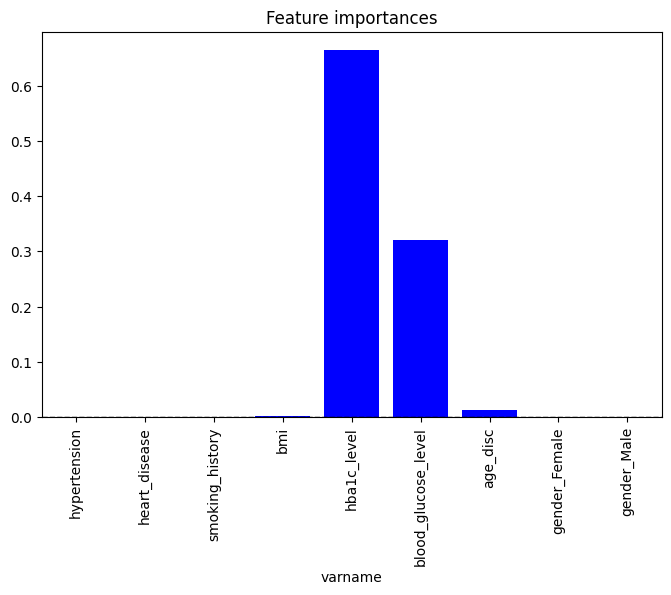

In [ ]:
#### START CODE HERE -- Decision Tree Global Interpretability ####

#Plot the feature importances and PLOT
importance = model.feature_importances_

#Plot the weights
coef_df = pd.DataFrame({'coef': importance,
                        'varname': X_train.columns
                       })

coef_df.plot(y='coef', x='varname', kind='bar', color='none', legend=False, figsize=(8,5))
plt.bar(coef_df['varname'], coef_df['coef'], color='blue')
plt.axhline(y=0, linestyle='--', color='black', linewidth=1)
#plt.title("Coefficients of Logistic Regression")
plt.title("Feature importances")
plt.show()

#### END CODE HERE ####

In [ ]:
# Feature importances
importances = model.feature_importances_

# Display feature importances
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df)

               Feature  Importance
4          hba1c_level    0.665046
5  blood_glucose_level    0.320518
6             age_disc    0.013182
3                  bmi    0.001253
0         hypertension    0.000000
1        heart_disease    0.000000
2      smoking_history    0.000000
7        gender_Female    0.000000
8          gender_Male    0.000000


In [ ]:
# Compute the number of nodes
num_nodes = model.tree_.node_count
print(num_nodes)

11


In [ ]:
# Compute the number of splits
num_splits = num_nodes - 1  # Total number of splits is one less than the number of nodes
print(num_splits)

10


In [ ]:
#Compute the depth
depth = model.tree_.max_depth
print(depth)

4


### Exercise 1.4 — Local Interpretability: Decision Paths

Consider the instances *100, 150 and 200* of the train dataset.

* Find the individual paths of the instances.
* For each of the previous instances, calculate the length of each path from
the root node to the leaf node to which the instance belongs.

An individual path will look like

```

Instance 100 | Predicted: Diabetes | Actual: Diabetes
Path length: 2 nodes
  Node 0: hba1c_level = 0.855  >  0.582
  → Leaf 10: class = Diabetes

```

* How does the
length of these paths contribute to the interpretability of the decision tree
locally?

In [ ]:
#@title Exercise 1.4 Solution
print("\n--- Local Interpretability: Decision Paths ---")
instance_indices = [100, 150, 200]


#### START CODE HERE -- Decision Tree Local Interpretability ####
node_indicator = model.decision_path(X_train)
leaf_id = model.apply(X_train)
threshold = model.tree_.threshold
feature_idx = model.tree_.feature

for sample_id in instance_indices:
    node_ids = node_indicator[sample_id].indices
    pred = model.predict(X_train.iloc[[sample_id]])[0]
    actual = y_train.iloc[sample_id]
    print(f"\n{'─'*55}")
    print(f"Instance {sample_id} | Predicted: {'Diabetes' if pred==1 else 'No Diabetes'} | Actual: {'Diabetes' if actual==1 else 'No Diabetes'}")
    print(f"Path length: {len(node_ids)} nodes")
    for node_id in node_ids[:-1]:
        feat = feature_names[feature_idx[node_id]]
        thresh = threshold[node_id]
        val = X_train.iloc[sample_id, feature_idx[node_id]]
        direction = "<=" if val <= thresh else ">"
        print(f"  Node {node_id}: {feat} = {val:.3f}  {direction}  {thresh:.3f}")
    print(f"  → Leaf {leaf_id[sample_id]}: class = {'Diabetes' if pred==1 else 'No Diabetes'}")
#### END CODE HERE ####



--- Local Interpretability: Decision Paths ---

───────────────────────────────────────────────────────
Instance 100 | Predicted: Diabetes | Actual: Diabetes
Path length: 2 nodes
  Node 0: hba1c_level = 0.855  >  0.582
  → Leaf 10: class = Diabetes

───────────────────────────────────────────────────────
Instance 150 | Predicted: No Diabetes | Actual: No Diabetes
Path length: 5 nodes
  Node 0: hba1c_level = 0.491  <=  0.582
  Node 1: blood_glucose_level = 0.295  <=  0.591
  Node 2: age_disc = 1.000  >  0.833
  Node 6: hba1c_level = 0.491  >  0.336
  → Leaf 8: class = No Diabetes

───────────────────────────────────────────────────────
Instance 200 | Predicted: No Diabetes | Actual: No Diabetes
Path length: 5 nodes
  Node 0: hba1c_level = 0.491  <=  0.582
  Node 1: blood_glucose_level = 0.091  <=  0.591
  Node 2: age_disc = 0.000  <=  0.833
  Node 3: bmi = 0.138  <=  0.341
  → Leaf 4: class = No Diabetes


> **Reflection:** Look at the path lengths for your three instances. A shorter path means fewer rules were needed — usually a more "clear-cut" case. Do instances with shorter paths have more extreme feature values (very high blood glucose, very high HbA1c)?

*Response:* instance 100 has the shortest path, only 2 nodes, because its hba1c_level = 0.855 is well above the root threshold 0.582; it is therefore a more clear-cut case for this tree. Instances 150 and 200 require 5-node paths because their values do not trigger such an immediate high-risk rule.  This supports the intended interpretation that shorter paths often correspond to cases that the tree separates using a more decisive feature value.

---

## Exercise 2 — Logistic Regression 📈

Logistic Regression is interpretable through its **coefficients** and derived **odds ratios**.
Unlike Linear regression, the interpretation of logistic regression weights varies since the outcome in logistic regression is a probability confined within the range of 0 to 1.
These weights undergo transformation through the logistic function, influencing the probability non-linearly.

- **Coefficient > 0** → feature increases the log-odds of the positive class (diabetes)
- **Coefficient < 0** → feature decreases the log-odds
- **Odds ratio = exp(coef)** → multiplicative change in odds for a 1-unit increase in the feature
  - OR > 1 → increases odds of diabetes
  - OR < 1 → decreases odds of diabetes
  - OR = 1 → no effect

### Your tasks
1.   Fit a [**Logistic Regression**](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression) model on the same dataset as before.

2.  Compute the Correlation Matrix.

3.  Evaluate the model using Precision, Recall and F1-score metrics.

4.  Analyze **Interpretability**:


> * Visualize the estimated **weights** and **odds ratios** obtained from logistic regression for each feature.
> * Put them into a tabular form and interpret the logistic regression model for different types of features. Specifically, analyze the ***bmi*** feature and ***gender_Male*** and ***gender_Female*** features.


### Exercise 2.1 — Fit & Evaluate

In [ ]:
from sklearn.linear_model import LogisticRegression

#### START CODE HERE ####
lr = LogisticRegression(max_iter=1000, C=0.1, random_state=42, solver='lbfgs')
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
#### END CODE HERE ####



--- Classification Report (Logistic Regression) ---
              precision    recall  f1-score   support

 No Diabetes       0.96      0.99      0.98     17530
    Diabetes       0.90      0.59      0.71      1696

    accuracy                           0.96     19226
   macro avg       0.93      0.79      0.85     19226
weighted avg       0.96      0.96      0.95     19226



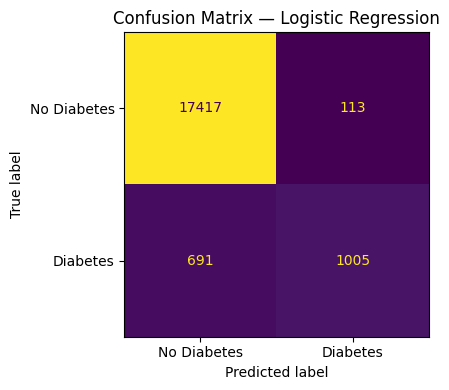

In [ ]:
print("\n--- Classification Report (Logistic Regression) ---")
print(classification_report(y_test, y_pred_lr, target_names=['No Diabetes', 'Diabetes']))

cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['No Diabetes','Diabetes'])
fig, ax = plt.subplots(figsize=(5, 4))
disp_lr.plot(ax=ax, colorbar=False)
ax.set_title('Confusion Matrix — Logistic Regression')
plt.tight_layout()

### Exercise 2.2 — Correlation Matrix

> 🔑 Before interpreting coefficients, always check for **multicollinearity** — when two features are
> highly correlated, the model distributes their shared explanatory power between them arbitrarily.
> This makes individual coefficients unreliable as explanations, even if the model's predictions are fine.

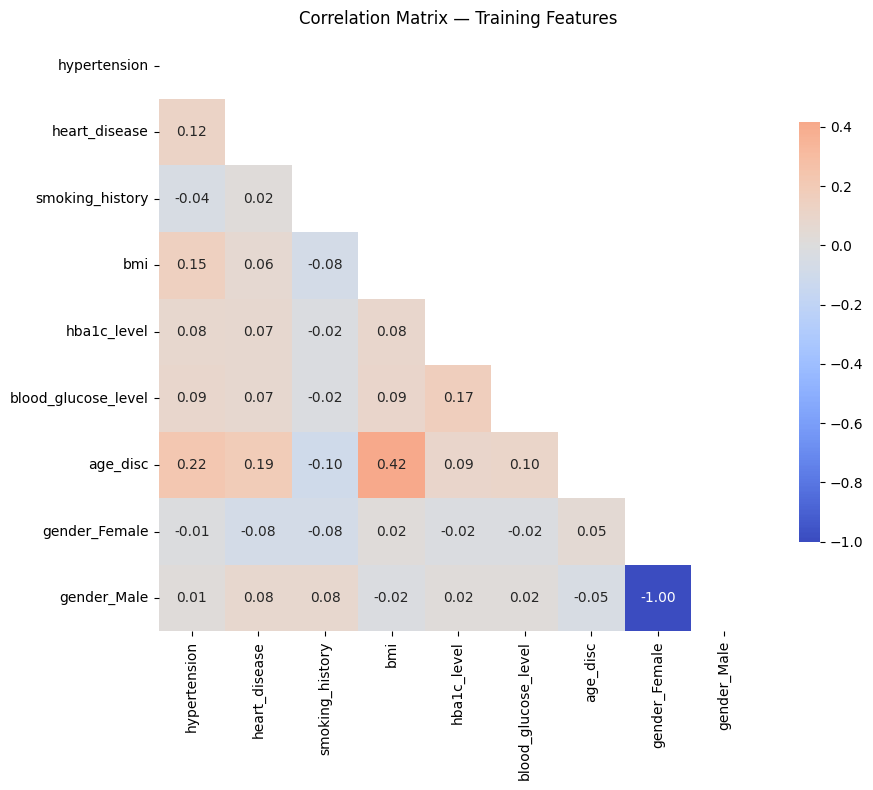

In [ ]:
#@title Exercise 2.2 Solution


#### START CODE HERE ####
fig, ax = plt.subplots(figsize=(10, 8))
corr = X_train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, ax=ax, cbar_kws={'shrink': 0.7})
ax.set_title('Correlation Matrix — Training Features')
plt.tight_layout()
#### END CODE HERE ####

### Exercise 2.3 — Coefficients Weights & Odds Ratios

* Print and plot feature names, coefficients and odd_ratios


--- Coefficients & Odds Ratios ---
            Feature  Coefficient   Odds Ratio
        hba1c_level     9.385502 11914.384927
blood_glucose_level     6.248479   517.225447
                bmi     4.190123    66.030922
           age_disc     3.104365    22.295062
      heart_disease     0.865893     2.377128
       hypertension     0.859923     2.362978
        gender_Male     0.139207     1.149361
      gender_Female    -0.124513     0.882927
    smoking_history    -0.242101     0.784977


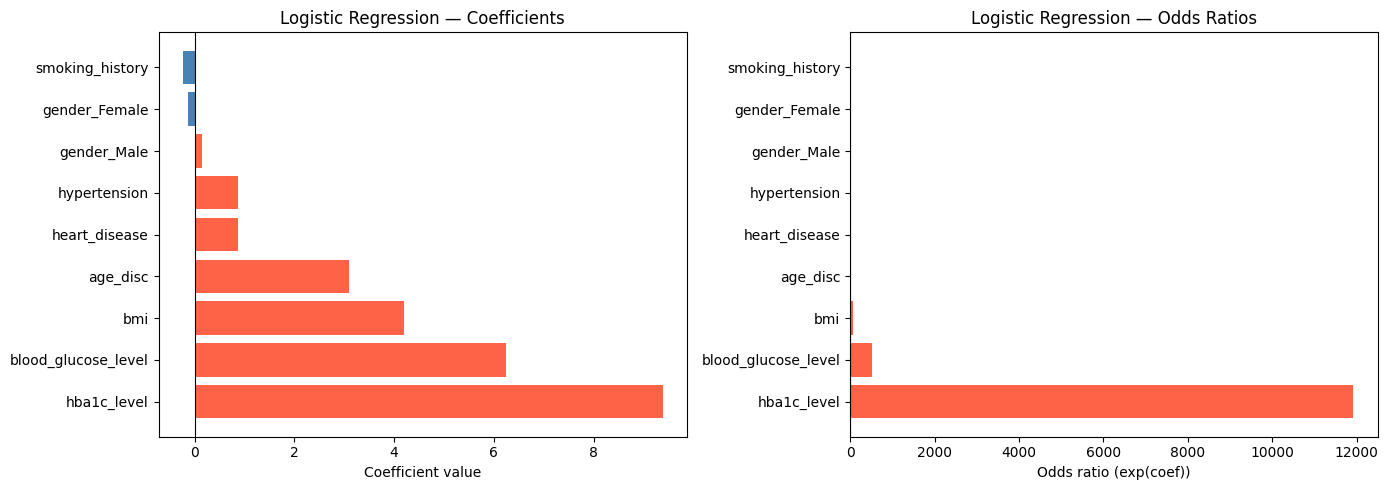

In [ ]:
#@title Exercise 2.3 Solution


#### START CODE HERE ####
coef = lr.coef_[0]
odds_ratios = np.exp(coef)

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef,
    'Odds Ratio': odds_ratios
}).sort_values('Coefficient', ascending=False)

print("\n--- Coefficients & Odds Ratios ---")
print(coef_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Coefficients
colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['Coefficient']]
axes[0].barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Logistic Regression — Coefficients')
axes[0].set_xlabel('Coefficient value')

# Odds Ratios
or_colors = ['tomato' if o > 1 else 'steelblue' for o in coef_df['Odds Ratio']]
axes[1].barh(coef_df['Feature'], coef_df['Odds Ratio'], color=or_colors)
axes[1].axvline(1, color='black', linewidth=0.8)
axes[1].set_title('Logistic Regression — Odds Ratios')
axes[1].set_xlabel('Odds ratio (exp(coef))')

plt.tight_layout()
#### END CODE HERE ####

In [ ]:
# Interpretation
bmi_row = coef_df[coef_df['Feature'] == 'bmi']
male_row = coef_df[coef_df['Feature'] == 'gender_Male'] if 'gender_Male' in coef_df['Feature'].values else None
female_row = coef_df[coef_df['Feature'] == 'gender_Female'] if 'gender_Female' in coef_df['Feature'].values else None

print("\n--- Feature Interpretations ---")
if not bmi_row.empty:
    b = bmi_row.iloc[0]
    print(f"BMI: coef={b['Coefficient']:.4f}, OR={b['Odds Ratio']:.4f}")
    print(f"  → A 1-unit increase in scaled BMI multiplies diabetes odds by {b['Odds Ratio']:.2f}x")
for name, row in [('gender_Male', male_row), ('gender_Female', female_row)]:
    if row is not None and not row.empty:
        r = row.iloc[0]
        direction = "increases" if r['Odds Ratio'] > 1 else "decreases"
        print(f"{name}: coef={r['Coefficient']:.4f}, OR={r['Odds Ratio']:.4f}")
        print(f"  → Being {name.split('_')[1]} {direction} the odds of diabetes by factor {r['Odds Ratio']:.2f}")


--- Feature Interpretations ---
BMI: coef=4.1901, OR=66.0309
  → A 1-unit increase in scaled BMI multiplies diabetes odds by 66.03x
gender_Male: coef=0.1392, OR=1.1494
  → Being Male increases the odds of diabetes by factor 1.15
gender_Female: coef=-0.1245, OR=0.8829
  → Being Female decreases the odds of diabetes by factor 0.88


## Exercise 3 — K-Nearest Neighbors 👥

KNN is an **instance-based learner**: there are no learned weights or tree structures to inspect.
In KNN, the prediction for a new data point is determined by the **majority** **class** (for classification) or the **mean** of the closest k neighbors' values (for regression) among the training data points, where *k* is a user-defined parameter.


Finding *k* can be tricky and you typically use techniques like cross-validation, **grid search**, or random search.

The interpretation and explanation of KNN does not follow procedures similar to the ones above. This because the KNN is an **instance-based learning algorithm** and so the interpretability comes entirely from **looking at the neighbors** used to make a prediction:

> *"This patient is predicted diabetic because their **6 most similar** patients in the training set were all diabetic."*


Hence, to explain a prediction in KNN:


1.   Retrieve the *k neighbors* that were used for the prediction.
2.   Analyze the k neighbors.

Hence, this is **purely local** interpretability — each prediction gets its own explanation given by its closest example.

### Your tasks

1. Find the best `k` parameter iterating over a range (1, 10) using a [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

> * Use the **best k** already found and fit a [**KNN**](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) on the same dataset as before.

> * Evaluate the KNN calculating the **mean accuracy** over test dataset.

2. Analyze **Interpretability** explaining 3 instances:

> * Consider the instances 100, 150 and 200 of the train dataset.
> * **Check** the **predicted target** for each instance.
> * **Retrieve** the relative k-nearest neighbors.
> * To **explain** the **predicted target** check the predicted targets for each of the k-nearest neighbors.

### Exercise 3.1 — Grid Search for Best K

* Use `GridSearchCV` to find the best k (`param_grid = {'n_neighbors': list(range(1, 10))}`
* Print the best training accuracy
* Train a KNN with the best k

In [ ]:
#@title Exercise 3.1 Solution

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

#### START CODE HERE ####
param_grid = {'n_neighbors': list(range(1, 10))}
knn_cv = GridSearchCV(KNeighborsClassifier(), param_grid,
                      cv=5, scoring='accuracy', n_jobs=-1)
knn_cv.fit(X_train, y_train)

best_k = knn_cv.best_params_['n_neighbors']
cv_results = pd.DataFrame(knn_cv.cv_results_)
#### END CODE HERE ####

print(f"Best k = {best_k}  (CV accuracy = {knn_cv.best_score_:.4f})")
# Best k = 6  (CV accuracy = 0.9629)

Best k = 6  (CV accuracy = 0.9629)


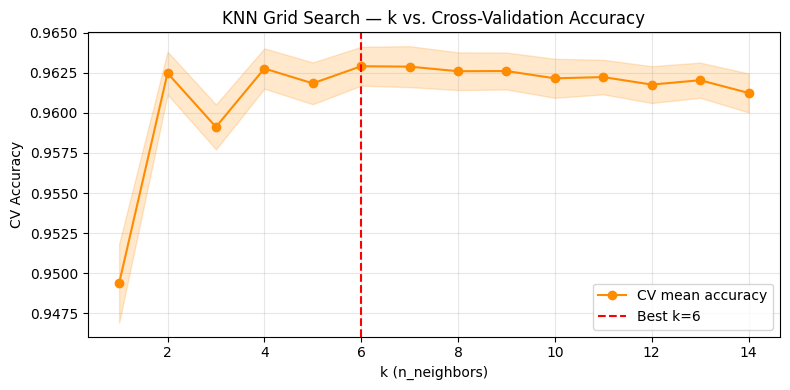

In [ ]:
# Plot CV scores
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 15), cv_results['mean_test_score'], 'o-', color='darkorange', label='CV mean accuracy')
ax.fill_between(range(1, 15),
                cv_results['mean_test_score'] - cv_results['std_test_score'],
                cv_results['mean_test_score'] + cv_results['std_test_score'],
                alpha=0.2, color='darkorange')
ax.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
ax.set_xlabel('k (n_neighbors)')
ax.set_ylabel('CV Accuracy')
ax.set_title('KNN Grid Search — k vs. Cross-Validation Accuracy')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

In [ ]:
# Fit final KNN with best k
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=6)

### Exercise 3.2 — Mean Accuracy over test dataset

* Compute the mean accuracy on test set
* Print/plot the classification report and confusion matrix


KNN (k=6) — Mean accuracy on test set: 0.9637

--- Classification Report (KNN) ---
              precision    recall  f1-score   support

 No Diabetes       0.96      1.00      0.98     17530
    Diabetes       0.96      0.61      0.75      1696

    accuracy                           0.96     19226
   macro avg       0.96      0.81      0.86     19226
weighted avg       0.96      0.96      0.96     19226



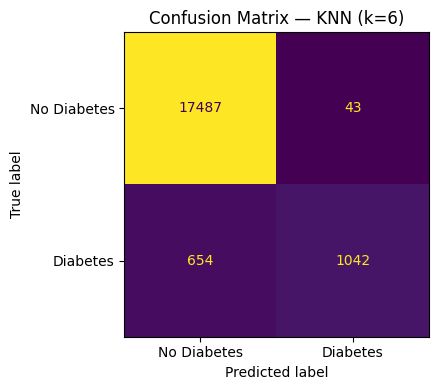

In [ ]:
#@title Exercise 3.2 Solution


#### START CODE HERE ####
test_accuracy = knn.score(X_test, y_test)
print(f"\nKNN (k={best_k}) — Mean accuracy on test set: {test_accuracy:.4f}")

y_pred_knn = knn.predict(X_test)
print("\n--- Classification Report (KNN) ---")
print(classification_report(y_test, y_pred_knn, target_names=['No Diabetes', 'Diabetes']))

cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['No Diabetes','Diabetes'])
fig, ax = plt.subplots(figsize=(5, 4))
disp_knn.plot(ax=ax, colorbar=False)
ax.set_title(f'Confusion Matrix — KNN (k={best_k})')
plt.tight_layout()
#### END CODE HERE ####

### Exercise 3.3 — Explain 3 instances

* Explain instances [100, 150, 200] by inspecting the KNN model (`knn.kneighbors`)
* You should be able to generate an explanation in this format:
```
Instance 100
  Predicted : Diabetes
  Actual    : Diabetes
  k=6 neighbors → 6 Diabetes | 0 No Diabetes
  Confidence: 100% majority vote

  Neighbors (key features):
   blood_glucose_level  hba1c_level       bmi  diabetes  distance
96371             0.272727     0.854545  0.312170         1  0.000000
90797             0.295455     0.854545  0.356414         1  0.049740
51696             0.227273     0.854545  0.339631         1  0.053106
48413             0.340909     0.854545  0.287877         1  0.072380
70050             0.359091     0.854545  0.370262         1  0.104083
74568             0.209091     0.854545  0.229668         1  0.104193

```


In [ ]:
#### START CODE HERE
print("\n--- Local Interpretability: Neighbor Inspection ---")

X_train_arr = X_train.values
y_train_arr = y_train.values

for sample_id in [100, 150, 200]:
    instance = X_train.iloc[[sample_id]]
    predicted = knn.predict(instance)[0]
    actual    = y_train.iloc[sample_id]

    distances, neighbor_indices = knn.kneighbors(instance)
    neighbor_labels = y_train_arr[neighbor_indices[0]]
    n_diabetic = neighbor_labels.sum()
    n_non      = best_k - n_diabetic

    print(f"\n{'─'*55}")
    print(f"Instance {sample_id}")
    print(f"  Predicted : {'Diabetes' if predicted==1 else 'No Diabetes'}")
    print(f"  Actual    : {'Diabetes' if actual==1 else 'No Diabetes'}")
    print(f"  k={best_k} neighbors → {int(n_diabetic)} Diabetes | {int(n_non)} No Diabetes")
    print(f"  Confidence: {max(n_diabetic, n_non)/best_k*100:.0f}% majority vote")

    neighbor_df = X_train.iloc[neighbor_indices[0]].copy()
    neighbor_df['diabetes'] = neighbor_labels
    neighbor_df['distance'] = distances[0]
    print(f"\n  Neighbors (key features):")
    display_cols = ['blood_glucose_level', 'hba1c_level', 'bmi', 'diabetes', 'distance']
    display_cols = [c for c in display_cols if c in neighbor_df.columns]
    print(neighbor_df[display_cols].to_string())####

#### END CODE HERE ####


--- Local Interpretability: Neighbor Inspection ---

───────────────────────────────────────────────────────
Instance 100
  Predicted : Diabetes
  Actual    : Diabetes
  k=6 neighbors → 6 Diabetes | 0 No Diabetes
  Confidence: 100% majority vote

  Neighbors (key features):
       blood_glucose_level  hba1c_level       bmi  diabetes  distance
96371             0.272727     0.854545  0.312170         1  0.000000
90797             0.295455     0.854545  0.356414         1  0.049740
51696             0.227273     0.854545  0.339631         1  0.053106
48413             0.340909     0.854545  0.287877         1  0.072380
70050             0.359091     0.854545  0.370262         1  0.104083
74568             0.209091     0.854545  0.229668         1  0.104193

───────────────────────────────────────────────────────
Instance 150
  Predicted : No Diabetes
  Actual    : No Diabetes
  k=6 neighbors → 0 Diabetes | 6 No Diabetes
  Confidence: 100% majority vote

  Neighbors (key features):
     

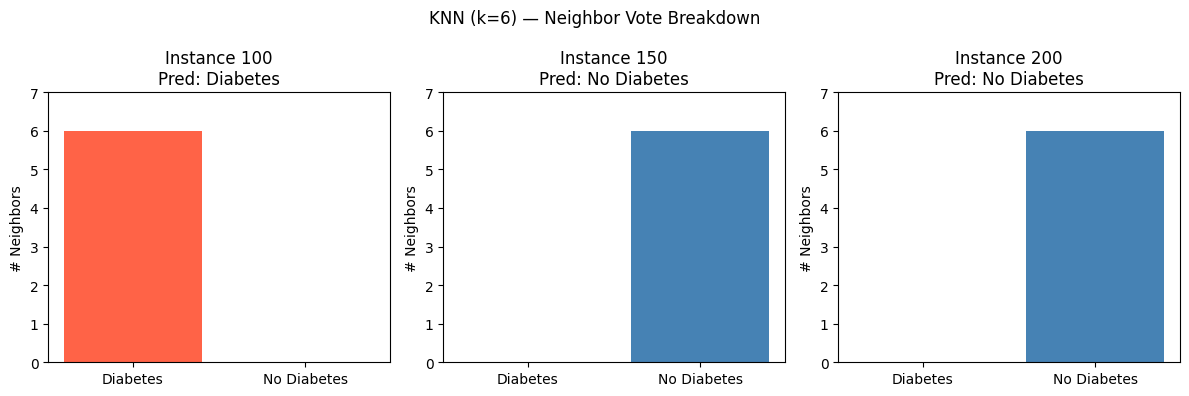

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, sample_id in zip(axes, [100, 150, 200]):
    instance = X_train.iloc[[sample_id]]
    predicted = knn.predict(instance)[0]
    _, neighbor_indices = knn.kneighbors(instance)
    neighbor_labels = y_train_arr[neighbor_indices[0]]
    n_d = int(neighbor_labels.sum())
    n_n = best_k - n_d
    ax.bar(['Diabetes', 'No Diabetes'], [n_d, n_n],
           color=['tomato', 'steelblue'])
    ax.set_title(f"Instance {sample_id}\nPred: {'Diabetes' if predicted==1 else 'No Diabetes'}")
    ax.set_ylabel('# Neighbors')
    ax.set_ylim(0, best_k + 1)
plt.suptitle(f'KNN (k={best_k}) — Neighbor Vote Breakdown', fontsize=12)
plt.tight_layout()

### 🔍 Reflection Questions

1. **Decision Tree:** The depth–accuracy plot shows that depth=4 costs some performance. Is that trade-off justified for a medical application like diabetes prediction — and *who* needs to read this model (clinician? regulator? patient)?

*Possible response:* The depth–accuracy trade-off can be justified if the simpler tree is substantially easier for the intended user to inspect. In this notebook, the tree is shallow (max_depth = 4) and uses mainly hba1c_level and blood_glucose_level, with very small contributions from the remaining features.  In a medical setting, the acceptable loss in performance depends on the audience and use case. A clinician may benefit from a compact tree that can be checked quickly, a regulator may prioritize auditability and reproducibility, while a patient-facing explanation may need even simpler language. The trade-off is justified only if the loss in predictive quality is small enough relative to the gain in transparency.

2. **Logistic Regression:** `blood_glucose_level` and `HbA1c_level` are likely correlated. If both have large positive coefficients, can you trust either one in isolation as an explanation? What would you do before presenting these to a doctor?

*Possible response:*No, the coefficients of blood_glucose_level and hba1c_level should not automatically be interpreted independently if the two variables are correlated. In multivariate logistic regression, each coefficient represents the association of that feature with the outcome holding the other features fixed. If two predictors are strongly correlated, coefficient magnitudes may become unstable and the apparent contribution may be distributed between them. Before presenting the model to a doctor, I would inspect the correlation matrix, check coefficient stability across resamples or folds, examine confidence intervals if available, and consider whether both variables should remain in the model. The clinical interpretation should also emphasize that these are model associations, not causal effects.

3. **KNN:** When an instance's neighbors are split (e.g. 4 vs. 2), the model is less "certain". How could you expose that uncertainty meaningfully? Would a clinician trust a prediction backed by only 4 out of 6 neighbors?

*Possible response:* A split such as 4 diabetic versus 2 non-diabetic neighbors can be reported as a local vote proportion:
\[
\frac{4}{6}\approx 0.67.
\]
Instead of returning only the predicted class, I would expose the neighborhood itself, the vote distribution, and the distances to those neighbors. A useful explanation would be:
Prediction: Diabetes; 4 of 6 nearest neighbors are diabetic; local vote agreement = 67%.

This is much less compelling than the 6/6 neighbor agreement shown for the notebook examples, where all three inspected instances have 100% majority agreement.  A clinician should therefore treat 4/6 as weaker local evidence, especially if the neighbors are relatively distant or clinically heterogeneous. Also, the vote fraction is not necessarily a calibrated probability.

4. **General:** All three models are "interpretable by design" — but is interpretability the same as trustworthiness? Can you construct a scenario where a shallow Decision Tree gives a confidently *wrong* explanation?

*Possible response:*  Interpretability is not the same as trustworthiness. An interpretable model can still be wrong because of biased data, omitted variables, dataset shift, poor measurement, or an inappropriate decision boundary.
For example, suppose a shallow tree learns:
\[
\text{IF HbA1c} > 6.5 \Rightarrow \text{Diabetes}.
\]
That rule is easy to understand, but imagine the training data were collected almost entirely from older patients. The tree could confidently classify a younger patient using the same threshold even though the relationship in that subgroup is different. The explanation is perfectly transparent:
\[
\text{HbA1c exceeded threshold} \Rightarrow \text{Diabetes},
\]
but it can still be wrong because the learned rule does not generalize to that patient population.
